# 08.4 · Backpropagation on a two-layer network, by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/04-backpropagation-by-hand/lesson.ipynb)

Work through the three tables in the [README](README.md) with a pencil first. This notebook reproduces every number, trains the same network on XOR, and checks the gradients against TensorFlow.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow start-up messages
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

def sigmoid(z): return 1 / (1 + np.exp(-z))

x = np.array([1.0, 0.5])            # one customer, two scaled features
y = 1.0                             # they churned
W = np.array([[0.2, 0.6],           # W[i, j]: input i → hidden neuron j
              [-0.4, 0.1]])
b = np.array([0.0, 0.0])            # hidden biases
v = np.array([0.5, -0.3])           # hidden → output weights
c = 0.0                             # output bias
lr = 0.5

## 1. Forward pass

In [2]:
z_hidden = x @ W + b
h = sigmoid(z_hidden)
z_out = h @ v + c
y_hat = sigmoid(z_out)
loss = -np.log(y_hat)                       # y = 1, so only the first term of log loss remains
print("z_hidden:", z_hidden.round(4), " h:", h.round(4))
print(f"z_out: {z_out:.4f}  y_hat: {y_hat:.4f}  loss: {loss:.3f}")

z_hidden: [0.   0.65]  h: [0.5   0.657]
z_out: 0.0529  y_hat: 0.5132  loss: 0.667


## 2. Backward pass, one line per row of the README table

In [3]:
d_out = y_hat - y
dv, dc = d_out * h, d_out
dh = d_out * v
d_hidden = dh * h * (1 - h)
dW = np.outer(x, d_hidden)
print(f"d_out = {d_out:.4f}")
print("dL/dv =", dv.round(4), "  dL/dc =", round(dc, 4))
print("dL/dh =", dh.round(4), "  delta_hidden =", d_hidden.round(4))
print("dL/dW =\n", dW.round(4))

d_out = -0.4868
dL/dv = [-0.2434 -0.3198]   dL/dc = -0.4868
dL/dh = [-0.2434  0.146 ]   delta_hidden = [-0.0608  0.0329]
dL/dW =
 [[-0.0608  0.0329]
 [-0.0304  0.0165]]


`np.outer(x, d_hidden)` builds the 2 × 2 table of $x_i \times \delta_j$: row $i$ is an input, column $j$ a hidden neuron, the same layout as `W`.

## 3. Update, then forward again

In [4]:
W_new, b_new = W - lr * dW, b - lr * d_hidden
v_new, c_new = v - lr * dv, c - lr * dc
print("new v:", v_new.round(4), " new c:", round(c_new, 4))
print("new W:\n", W_new.round(4), "\nnew b:", b_new.round(4))
y_hat_new = sigmoid(sigmoid(x @ W_new + b_new) @ v_new + c_new)
print(f"\nprediction {y_hat:.4f} → {y_hat_new:.4f},  loss {loss:.3f} → {-np.log(y_hat_new):.3f}")

new v: [ 0.6217 -0.1401]  new c: 0.2434
new W:
 [[ 0.2304  0.5835]
 [-0.3848  0.0918]] 
new b: [ 0.0304 -0.0165]

prediction 0.5132 → 0.6163,  loss 0.667 → 0.484


Exactly the README's numbers: one step moved the prediction for a churner from 0.513 to 0.616.

## 4. Package it up and learn XOR

XOR: output 1 when exactly one input is 1. No single straight line separates the 1s from the 0s, so a single neuron cannot learn it (lesson 08.2). The 2-2-1 network can.

In [5]:
def forward(x, W, b, v, c):
    h = sigmoid(x @ W + b)
    y_hat = sigmoid(h @ v + c)
    return h, y_hat

def backward(x, y, W, b, v, c):
    """Gradients of the log loss for one example, exactly as in the README table."""
    h, y_hat = forward(x, W, b, v, c)
    d_out = y_hat - y                       # dL/dz_out
    dv, dc = d_out * h, d_out               # output weights and bias
    dh = d_out * v                          # dL/dh_j
    d_hidden = dh * h * (1 - h)             # dL/dz_j
    dW = np.outer(x, d_hidden)              # dW[i, j] = x_i * delta_j
    return dW, d_hidden, dv, dc

def log_loss(y, y_hat):
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0], dtype=float)

def train_xor(seed, steps=1000, lr=2.0, hidden=2):
    """Full-batch gradient descent on the 4 XOR cases, averaging gradients over them."""
    rng = np.random.default_rng(seed)
    W, b = rng.normal(0, 1, (2, hidden)), np.zeros(hidden)
    v, c = rng.normal(0, 1, hidden), 0.0
    losses = []
    for _ in range(steps):
        grads = [backward(xi, yi, W, b, v, c) for xi, yi in zip(X_xor, y_xor)]
        W = W - lr * np.mean([g[0] for g in grads], axis=0); b = b - lr * np.mean([g[1] for g in grads], axis=0)
        v = v - lr * np.mean([g[2] for g in grads], axis=0); c = c - lr * np.mean([g[3] for g in grads])
        losses.append(np.mean([log_loss(yi, forward(xi, W, b, v, c)[1]) for xi, yi in zip(X_xor, y_xor)]))
    return (W, b, v, c), losses

params, losses = train_xor(seed=0)
preds = [forward(xi, *params)[1] for xi in X_xor]
print("targets    :", y_xor)
print("predictions:", np.round(preds, 3))

targets    : [0. 1. 1. 0.]
predictions: [0.009 0.992 0.989 0.007]


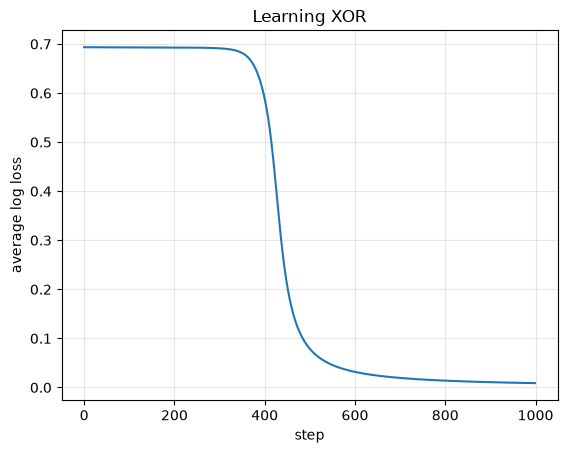

In [6]:
plt.plot(losses)
plt.xlabel("step"); plt.ylabel("average log loss"); plt.title("Learning XOR")
plt.grid(alpha=.3); plt.show()

## 5. What the hidden layer learned

Each hidden neuron draws one straight line. The output neuron combines them into a band that contains (0, 1) and (1, 0) but not the corners.

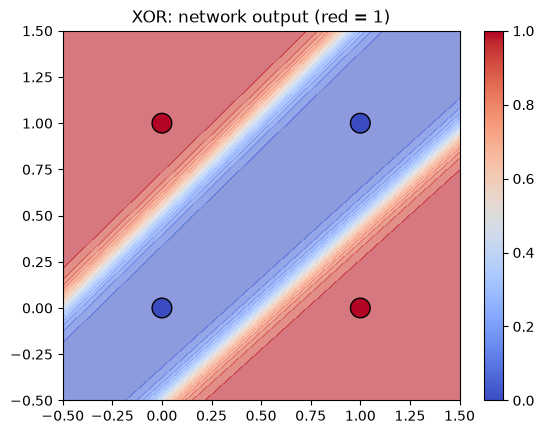

In [7]:
g = np.linspace(-0.5, 1.5, 200)
gx, gy = np.meshgrid(g, g)
grid = np.c_[gx.ravel(), gy.ravel()]
out = np.array([forward(p, *params)[1] for p in grid]).reshape(gx.shape)
plt.contourf(gx, gy, out, levels=20, cmap="coolwarm", alpha=.6)
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=200, edgecolors="black")
plt.title("XOR: network output (red = 1)"); plt.colorbar(); plt.show()

## 6. A run that gets stuck

Same network, same data, different random starting weights.

In [8]:
params5, losses5 = train_xor(seed=5)
print("seed 5 predictions:", np.round([forward(xi, *params5)[1] for xi in X_xor], 3))
print(f"final loss: seed 0 {losses[-1]:.3f}, seed 5 {losses5[-1]:.3f}")

seed 5 predictions: [0.339 0.992 0.333 0.336]
final loss: seed 0 0.009, seed 5 0.483


Seed 5 gets one case right and sits at about 0.34 for the other three. It has reached a **plateau**: the loss surface is nearly flat there, so the gradients are tiny and 1,000 steps are not enough to get across. Exercise 4 tries three ways out.

## 7. Let TensorFlow do the backward pass

`tf.GradientTape` records the forward pass, then computes every gradient automatically. Same starting weights, same customer.

In [9]:
import tensorflow as tf
tW, tb, tv, tc = (tf.Variable(a, dtype=tf.float64) for a in (W, b, v, c))
with tf.GradientTape() as tape:
    h_tf = tf.sigmoid(tf.linalg.matvec(tf.transpose(tW), tf.constant(x)) + tb)
    y_tf = tf.sigmoid(tf.reduce_sum(h_tf * tv) + tc)
    loss_tf = -tf.math.log(y_tf)
gW, gb, gv, gc = tape.gradient(loss_tf, [tW, tb, tv, tc])
print("dL/dW  TensorFlow:\n", gW.numpy().round(4), "\n       by hand:\n", dW.round(4))
print("dL/dv  TensorFlow:", gv.numpy().round(4), " by hand:", dv.round(4))
print("dL/dc  TensorFlow:", round(float(gc), 4), " by hand:", round(dc, 4))

dL/dW  TensorFlow:
 [[-0.0608  0.0329]
 [-0.0304  0.0165]] 
       by hand:
 [[-0.0608  0.0329]
 [-0.0304  0.0165]]
dL/dv  TensorFlow: [-0.2434 -0.3198]  by hand: [-0.2434 -0.3198]
dL/dc  TensorFlow: -0.4868  by hand: -0.4868


Identical. This is what Keras runs inside `model.fit()` for every batch, for every weight. From lesson 08.5 on, you let it.

## Quiz answers

1. The forward pass computes every neuron's output and the loss. The backward pass computes the derivative of the loss with respect to every weight and bias.
2. Because the derivatives are computed starting from the loss at the output and moving backwards through the layers; each layer's result is reused for the layer before it.
3. $\hat y - y$: prediction minus truth.
4. Hidden neuron 2 feeds the output through a negative weight ($v_2 = -0.3$), so its activity pushed the prediction down. The output needed to go up, so the update reduced that neuron's activity by lowering its input weights.
5. It records the operations of a forward pass and then computes the gradient of a result (the loss) with respect to chosen variables, using backpropagation automatically.

**Next:** [08.5 Your first network in Keras](../05-first-keras-network/)